# Embedding-Based WSD Classifier

Train MLP classifiers on contextual embeddings to predict word senses (using LLM labels as ground truth).

**Data**: `passio_sample1000_classified.parquet`, `pathos_sample1000_classified.parquet`

**Embeddings tested**:
- LaBERT WSD (layers 7, 11)
- PhilBerta (layers 7, 11)

**Labels**: `class_llama3.3` (LLM-based sense classifications)

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix

# Helper modules are in the same directory
import classification_helpers

## Load Data

In [2]:
passio_df = pd.read_parquet("../data/large_files/passio_sample1000_classified.parquet")
pathos_df = pd.read_parquet("../data/large_files/pathos_sample1000_classified.parquet")

print(f"Passio: {len(passio_df)} rows")
print(f"Pathos: {len(pathos_df)} rows")

Passio: 1000 rows
Pathos: 1000 rows


## Label Distributions

In [3]:
print("=== PASSIO - class_llama3.3 ===")
print(passio_df["class_llama3.3"].value_counts().sort_index())
print(f"\nUnique classes: {passio_df['class_llama3.3'].nunique()}")

=== PASSIO - class_llama3.3 ===
class_llama3.3
0.0    125
1.0     60
2.0    143
3.0    373
4.0     72
5.0    226
Name: count, dtype: int64

Unique classes: 6


In [4]:
print("=== PATHOS - class_llama3.3 ===")
print(pathos_df["class_llama3.3"].value_counts().sort_index())
print(f"\nUnique classes: {pathos_df['class_llama3.3'].nunique()}")

=== PATHOS - class_llama3.3 ===
class_llama3.3
0    350
1    182
2    311
3    114
4     43
Name: count, dtype: int64

Unique classes: 5


## Define Embedding Columns to Test

In [5]:
EMB_COLS = [
    "emb_labert_wsd_l7",
    "emb_labert_wsd_l11",
    "emb_philberta_l7",
    "emb_philberta_l11"
]

LABEL_COL = "class_llama3.3"

# Filter out rows with NaN labels (passio has 1 such row)
print(f"Passio NaN labels before filtering: {passio_df[LABEL_COL].isna().sum()}")
print(f"Pathos NaN labels before filtering: {pathos_df[LABEL_COL].isna().sum()}")

passio_df = passio_df.dropna(subset=[LABEL_COL])
pathos_df = pathos_df.dropna(subset=[LABEL_COL])

print(f"Passio rows after filtering: {len(passio_df)}")
print(f"Pathos rows after filtering: {len(pathos_df)}")

Passio NaN labels before filtering: 1
Pathos NaN labels before filtering: 0
Passio rows after filtering: 999
Pathos rows after filtering: 1000


## Evaluation Function

In [7]:
def evaluate_embedding_model(df, emb_col, label_col=LABEL_COL, cv=5):
    """Evaluate MLP classifier on a single embedding column."""
    X, y = classification_helpers.prepare_classification_data(df, emb_col, label_col)
    clf = classification_helpers.create_mlp_classifier()
    result = classification_helpers.evaluate_classifier(X, y, clf, cv=cv)
    return result

## Evaluate All Embedding Models (Passio)

In [8]:
passio_results = {}

for emb_col in EMB_COLS:
    print(f"Evaluating {emb_col}...")
    result = evaluate_embedding_model(passio_df, emb_col)
    passio_results[emb_col] = result
    print(f"  Accuracy: {result['accuracy']:.4f}")
    print(f"  F1 Macro: {result['f1_macro']:.4f}")
    print()

Evaluating emb_labert_wsd_l7...
  Accuracy: 0.5716
  F1 Macro: 0.4674

Evaluating emb_labert_wsd_l11...
  Accuracy: 0.6897
  F1 Macro: 0.6128

Evaluating emb_philberta_l7...
  Accuracy: 0.6166
  F1 Macro: 0.5390

Evaluating emb_philberta_l11...
  Accuracy: 0.6877
  F1 Macro: 0.6167



In [9]:
passio_results_df = pd.DataFrame([
    {
        "embedding": emb_col,
        "accuracy": result["accuracy"],
        "f1_macro": result["f1_macro"]
    }
    for emb_col, result in passio_results.items()
])

passio_results_df.to_markdown(index=False)

'| embedding          |   accuracy |   f1_macro |\n|:-------------------|-----------:|-----------:|\n| emb_labert_wsd_l7  |   0.571572 |   0.467436 |\n| emb_labert_wsd_l11 |   0.68969  |   0.612755 |\n| emb_philberta_l7   |   0.616617 |   0.538978 |\n| emb_philberta_l11  |   0.687688 |   0.616683 |'

## Evaluate All Embedding Models (Pathos)

In [10]:
pathos_results = {}

for emb_col in EMB_COLS:
    print(f"Evaluating {emb_col}...")
    result = evaluate_embedding_model(pathos_df, emb_col)
    pathos_results[emb_col] = result
    print(f"  Accuracy: {result['accuracy']:.4f}")
    print(f"  F1 Macro: {result['f1_macro']:.4f}")
    print()

Evaluating emb_labert_wsd_l7...
  Accuracy: 0.3690
  F1 Macro: 0.3094

Evaluating emb_labert_wsd_l11...
  Accuracy: 0.3460
  F1 Macro: 0.2749

Evaluating emb_philberta_l7...
  Accuracy: 0.5400
  F1 Macro: 0.4390

Evaluating emb_philberta_l11...
  Accuracy: 0.5870
  F1 Macro: 0.5338



In [11]:
pathos_results_df = pd.DataFrame([
    {
        "embedding": emb_col,
        "accuracy": result["accuracy"],
        "f1_macro": result["f1_macro"]
    }
    for emb_col, result in pathos_results.items()
])

pathos_results_df.to_markdown(index=False)

'| embedding          |   accuracy |   f1_macro |\n|:-------------------|-----------:|-----------:|\n| emb_labert_wsd_l7  |      0.369 |   0.309445 |\n| emb_labert_wsd_l11 |      0.346 |   0.274908 |\n| emb_philberta_l7   |      0.54  |   0.439026 |\n| emb_philberta_l11  |      0.587 |   0.533831 |'

## Compare Results Visualization

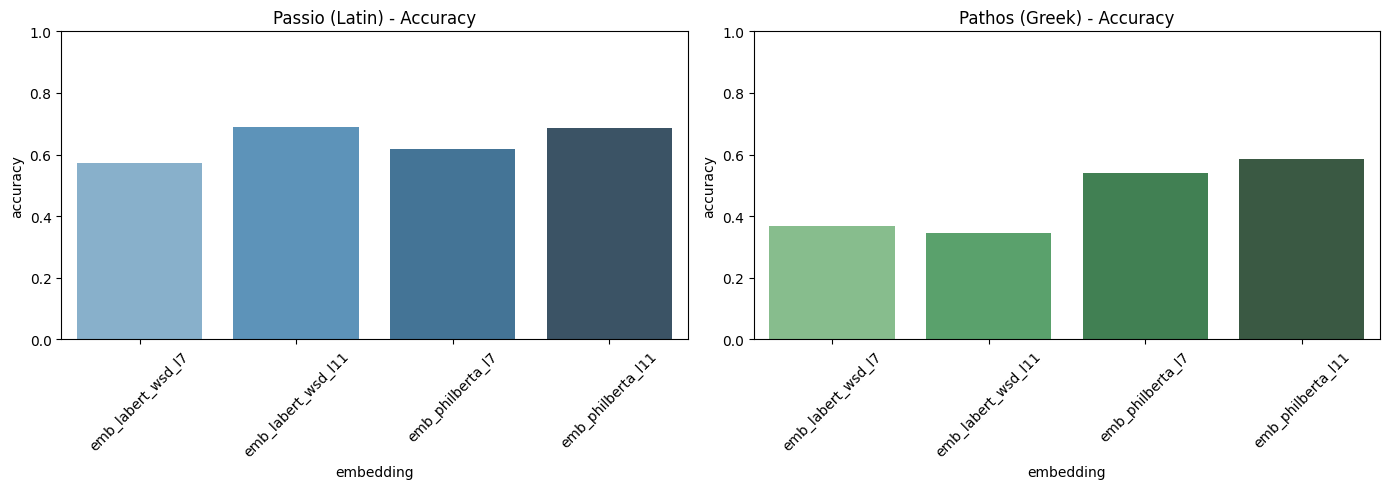

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Passio
sns.barplot(
    data=passio_results_df,
    x="embedding",
    y="accuracy",
    ax=axes[0],
    palette="Blues_d"
)
axes[0].set_title("Passio (Latin) - Accuracy")
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_ylim(0, 1)

# Pathos
sns.barplot(
    data=pathos_results_df,
    x="embedding",
    y="accuracy",
    ax=axes[1],
    palette="Greens_d"
)
axes[1].set_title("Pathos (Greek) - Accuracy")
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig("../figures/embedding-classifier-comparison.png", dpi=150, bbox_inches='tight')
plt.show()

## Merged Embeddings Experiment

In [13]:
# Test merging top embeddings from both models (layer 11)
X_merged = classification_helpers.merge_multiple_embeddings(
    passio_df, 
    ["emb_labert_wsd_l11", "emb_philberta_l11"], 
    method="mean"
)
print(f"Merged embedding shape: {X_merged.shape}")

# Evaluate merged embeddings
y = passio_df[LABEL_COL].values
clf_merged = classification_helpers.create_mlp_classifier()
result_merged = classification_helpers.evaluate_classifier(X_merged, y, clf_merged, cv=5)
print(f"Merged (mean) - Accuracy: {result_merged['accuracy']:.4f}, F1: {result_merged['f1_macro']:.4f}")

Merged embedding shape: (999, 768)
Merged (mean) - Accuracy: 0.7117, F1: 0.6208


In [14]:
# Same for pathos
X_merged_pathos = classification_helpers.merge_multiple_embeddings(
    pathos_df, 
    ["emb_labert_wsd_l11", "emb_philberta_l11"], 
    method="mean"
)
y_pathos = pathos_df[LABEL_COL].values
clf_merged_pathos = classification_helpers.create_mlp_classifier()
result_merged_pathos = classification_helpers.evaluate_classifier(X_merged_pathos, y_pathos, clf_merged_pathos, cv=5)
print(f"Pathos Merged (mean) - Accuracy: {result_merged_pathos['accuracy']:.4f}, F1: {result_merged_pathos['f1_macro']:.4f}")

Pathos Merged (mean) - Accuracy: 0.5490, F1: 0.4857


## Train Final Model (Best Configuration)

In [16]:
# Find best embedding for passio
best_passio = passio_results_df.loc[passio_results_df['accuracy'].idxmax()]
print(f"Best for Passio: {best_passio['embedding']} (acc={best_passio['accuracy']:.4f})")

# Train final model on full data
X_best, y_best = classification_helpers.prepare_classification_data(
    passio_df, best_passio['embedding'], LABEL_COL
)
clf_final = classification_helpers.create_mlp_classifier()
final_result = classification_helpers.evaluate_classifier(
    X_best, y_best, clf_final, cv=5, return_model=True
)

Best for Passio: emb_labert_wsd_l11 (acc=0.6897)


In [17]:
# Save the trained model
import joblib
joblib.dump(final_result['model'], f"../data/passio_wsd_{best_passio['embedding']}.pkl")
print(f"Model saved!")

Model saved!


## Summary

In [18]:
print("="*60)
print("SUMMARY")
print("="*60)

print("\n--- PASSIO ---")
for emb_col, result in passio_results.items():
    print(f"{emb_col}: acc={result['accuracy']:.4f}, f1={result['f1_macro']:.4f}")

print("\n--- PATHOS ---")
for emb_col, result in pathos_results.items():
    print(f"{emb_col}: acc={result['accuracy']:.4f}, f1={result['f1_macro']:.4f}")

print("\n--- MERGED EMBEDDINGS ---")
print(f"Passio merged: acc={result_merged['accuracy']:.4f}, f1={result_merged['f1_macro']:.4f}")
print(f"Pathos merged: acc={result_merged_pathos['accuracy']:.4f}, f1={result_merged_pathos['f1_macro']:.4f}")

SUMMARY

--- PASSIO ---
emb_labert_wsd_l7: acc=0.5716, f1=0.4674
emb_labert_wsd_l11: acc=0.6897, f1=0.6128
emb_philberta_l7: acc=0.6166, f1=0.5390
emb_philberta_l11: acc=0.6877, f1=0.6167

--- PATHOS ---
emb_labert_wsd_l7: acc=0.3690, f1=0.3094
emb_labert_wsd_l11: acc=0.3460, f1=0.2749
emb_philberta_l7: acc=0.5400, f1=0.4390
emb_philberta_l11: acc=0.5870, f1=0.5338

--- MERGED EMBEDDINGS ---
Passio merged: acc=0.7117, f1=0.6208
Pathos merged: acc=0.5490, f1=0.4857
